# 02. Разведочный анализ (EDA)

**Цель.** Посмотреть, как устроено поведение посетителей и чем сессии с покупкой отличаются от сессий без неё. Найти, от чего зависит *конверсия*, то есть доля сессий, закончившихся покупкой. В конце ноутбука будет список гипотез, которые я проверю статистически в 03 и использую при создании признаков в 04.

**Что уже известно из 01.**
- 12 330 сессий, покупкой заканчиваются 15.5%. Классы несбалансированы.
- Длительности занижены: время последней страницы визита, по-видимому, не записывается, поэтому у 720 сессий длительность ноль.
- Я работаю только с train (9864 сессии). Тест отложен.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import FEATURE_RU, MONTH_ORDER, MONTH_RU, TARGET, VISITOR_RU
from src.data import load_train
from src.plots import (AQUA, BLUE, CLASS_COLORS, CLASS_LABELS, DIV_CMAP, GRAY, INK_2,
                       ORANGE, save_fig, setup_style)
from src.stats_tests import conversion_table

setup_style()
pd.set_option("display.max_columns", 30)

train = load_train()
base_conv = train[TARGET].mean()
print(f"train: {len(train)} сессий, конверсия {base_conv:.1%}")

train: 9864 сессий, конверсия 15.5%


## 1. Распределения числовых признаков

**Что хочу проверить.** Как распределены количество страниц и время на них: есть ли длинные "хвосты", много ли нулей, отличаются ли распределения у тех, кто купил, и у тех, кто ушёл.

In [2]:
num_cols = list(FEATURE_RU)
summary = train[num_cols].describe(percentiles=[0.5, 0.9, 0.99]).T[["mean", "50%", "90%", "99%", "max"]]
summary["доля нулей"] = (train[num_cols] == 0).mean()
summary.round(3)

,mean,50%,90%,99%,max,доля нулей
Administrative,2.318,1.000,7.000,14.000,27.000,0.467
Administrative_Duration,81.241,8.000,223.638,868.383,3398.750,0.477
Informational,0.505,0.000,2.000,6.000,24.000,0.785
Informational_Duration,34.590,0.000,72.000,720.302,2549.375,0.805
ProductRelated,31.453,18.000,74.000,210.370,705.000,0.003
ProductRelated_Duration,1186.546,600.537,2859.664,8588.704,63973.522,0.062
BounceRates,0.022,0.003,0.060,0.200,0.200,0.448
ExitRates,0.043,0.025,0.100,0.200,0.200,0.006
PageValues,5.945,0.000,19.114,85.200,361.764,0.778
SpecialDay,0.063,0.000,0.200,1.000,1.000,0.897


**Что увидел.** У всех счётчиков и длительностей среднее заметно больше медианы, а максимум на порядки больше 99-го процентиля. Пример: у времени на товарных страницах медиана около 10 минут (601 сек), а максимум почти 18 часов (63 974 сек). Нулей много: 46.7% сессий без служебных страниц, 78.5% без информационных, 77.8% с `PageValues = 0`. Товарные страницы смотрят почти все (нулей 0.3%).

**Что это значит.** Распределения сильно скошены вправо: большинство визитов короткие, и есть немного очень длинных (возможно, вкладку просто забыли закрыть). Для логистической регрессии, которая чувствительна к масштабу, такие признаки стоит прологарифмировать, а для сравнения групп брать медианы, а не средние.

*Медиана* означает значение "посередине": половина сессий меньше, половина больше. В отличие от среднего, медиану не сдвигает одна сессия длиной 18 часов.

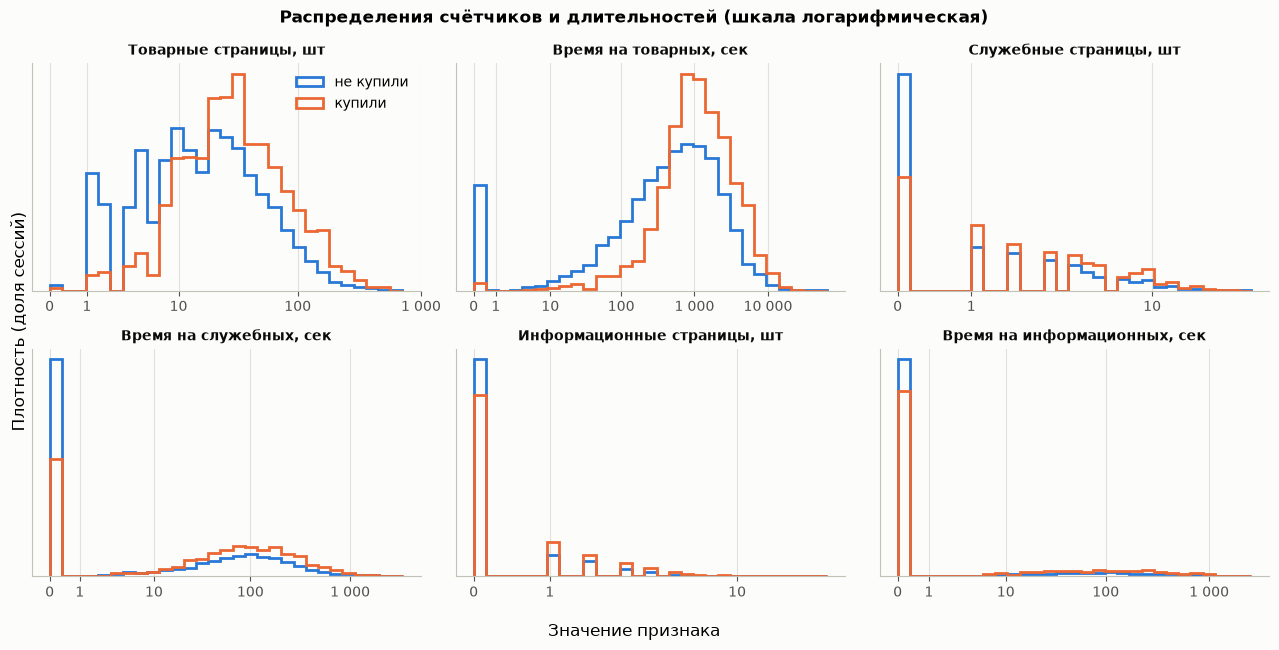

In [3]:
def log_ticks(ax, max_value):
    """Подписи оси в исходных единицах при логарифмической шкале log(1 + x)."""
    ticks = [t for t in [0, 1, 10, 100, 1000, 10000] if t <= max_value * 1.5]
    ax.set_xticks(np.log1p(ticks))
    ax.set_xticklabels([f"{t:,}".replace(",", " ") for t in ticks])

hist_cols = ["ProductRelated", "ProductRelated_Duration", "Administrative",
             "Administrative_Duration", "Informational", "Informational_Duration"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), hist_cols):
    values = np.log1p(train[col])
    bins = np.linspace(0, values.max(), 30)
    for cls in [0, 1]:
        ax.hist(values[train[TARGET] == cls], bins=bins, density=True,
                histtype="step", linewidth=2, color=CLASS_COLORS[cls],
                label=CLASS_LABELS[cls])
    ax.set_title(FEATURE_RU[col], fontsize=10)
    log_ticks(ax, train[col].max())
    ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Распределения счётчиков и длительностей (шкала логарифмическая)", fontweight="bold")
fig.supxlabel("Значение признака")
fig.supylabel("Плотность (доля сессий)")
fig.tight_layout()
save_fig(fig, "02_distributions")
plt.show()

In [4]:
print("Медианы по классам:")
train.groupby(TARGET)[num_cols].median().T.rename(columns=CLASS_LABELS).round(3)

Медианы по классам:


Revenue,не купили,купили
Administrative,0.000,2.000
Administrative_Duration,0.000,53.125
Informational,0.000,0.000
Informational_Duration,0.000,0.000
ProductRelated,16.000,29.000
ProductRelated_Duration,511.333,1120.850
BounceRates,0.004,0.000
ExitRates,0.029,0.016
PageValues,0.000,17.323
SpecialDay,0.000,0.000


**Что увидел.** У купивших распределения сдвинуты вправо почти по всем счётчикам: медиана товарных страниц 29 против 16, времени на них 1121 сек (около 19 минут) против 511 сек (около 8.5 минут). Медиана служебных страниц у купивших 2, у ушедших 0. По информационным страницам разница слабая: медиана в обеих группах ноль.

**Что это значит.** Купившие ведут себя активнее: больше смотрят и дольше остаются. Это ожидаемо, но тут есть ловушка: оформление заказа само по себе добавляет страницы и время. Часть разницы может быть не причиной покупки, а её следствием. К этому я вернусь в 03.

## 2. Конверсия по месяцам

**Что хочу проверить.** Есть ли сезонность. Ожидаю всплеск перед Новым годом.

На графиках ниже у каждого столбика есть *доверительный интервал* (чёрная черта). Это диапазон, в котором с вероятностью около 95% лежит "настоящая" конверсия группы. Чем меньше сессий в группе, тем он шире, то есть тем меньше можно доверять одному числу.

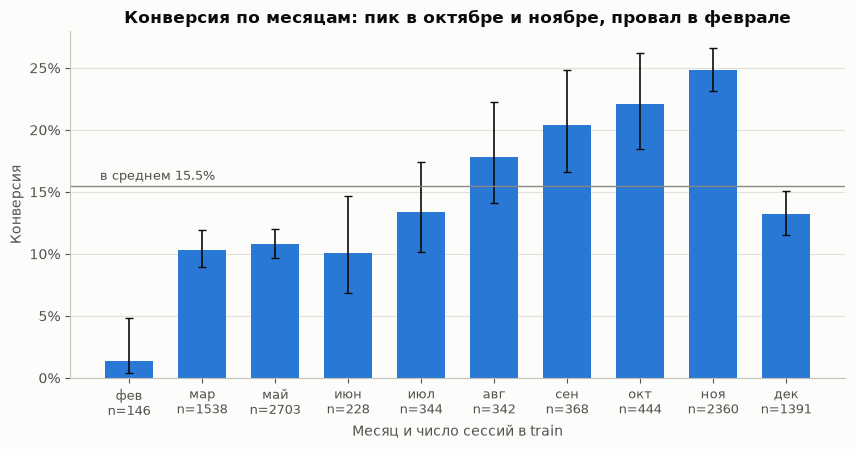

,sessions,purchases,conversion
Month,,,
Feb,146,2,0.014
Mar,1538,159,0.103
May,2703,292,0.108
Jun,228,23,0.101
Jul,344,46,0.134
Aug,342,61,0.178
Sep,368,75,0.204
Oct,444,98,0.221
Nov,2360,586,0.248


In [5]:
by_month = conversion_table(train, "Month").reindex(MONTH_ORDER)

def plot_conversion_bars(ax, table, labels, color=BLUE):
    x = np.arange(len(table))
    ax.bar(x, table["conversion"], color=color, width=0.65)
    ax.errorbar(x, table["conversion"],
                yerr=[table["conversion"] - table["ci_low"], table["ci_high"] - table["conversion"]],
                fmt="none", ecolor="#0b0b0b", elinewidth=1.2, capsize=3)
    ax.axhline(base_conv, color=GRAY, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{l}\nn={n}" for l, n in zip(labels, table["sessions"])], fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_conversion_bars(ax, by_month, [MONTH_RU[m] for m in MONTH_ORDER])
ax.text(-0.4, base_conv + 0.005, f"в среднем {base_conv:.1%}", ha="left", color=INK_2, fontsize=9)
ax.set_title("Конверсия по месяцам: пик в октябре и ноябре, провал в феврале")
ax.set_xlabel("Месяц и число сессий в train")
ax.set_ylabel("Конверсия")
save_fig(fig, "02_conversion_by_month")
plt.show()
by_month[["sessions", "purchases", "conversion"]].round(3)

**Что увидел.** Самая высокая конверсия в ноябре (24.8%) и октябре (22.1%), рядом сентябрь (20.4%). Самая низкая в феврале: 2 покупки на 146 сессий (1.4%). В мае и марте, самых многочисленных месяцах, конверсия ниже средней: 10.8% и 10.3%. Декабрь (13.2%) неожиданно ниже ноября.

**Что это значит.** Сезонность сильная: в ноябре покупают в 2.3 раза чаще, чем в мае. Возможная причина в предпраздничных распродажах (в ноябре обычно "чёрная пятница"), но это догадка: дат в данных нет. Для модели месяц будет полезным признаком. Но если в будущем "ноябрь" будет вести себя иначе, модель может ошибаться.

## 3. Тип посетителя, выходные и праздники

**Что хочу проверить.** Я ожидал, что вернувшиеся посетители покупают чаще новых (уже знают магазин), в выходные покупают чаще (больше свободного времени), а перед праздниками тоже чаще (подарки).

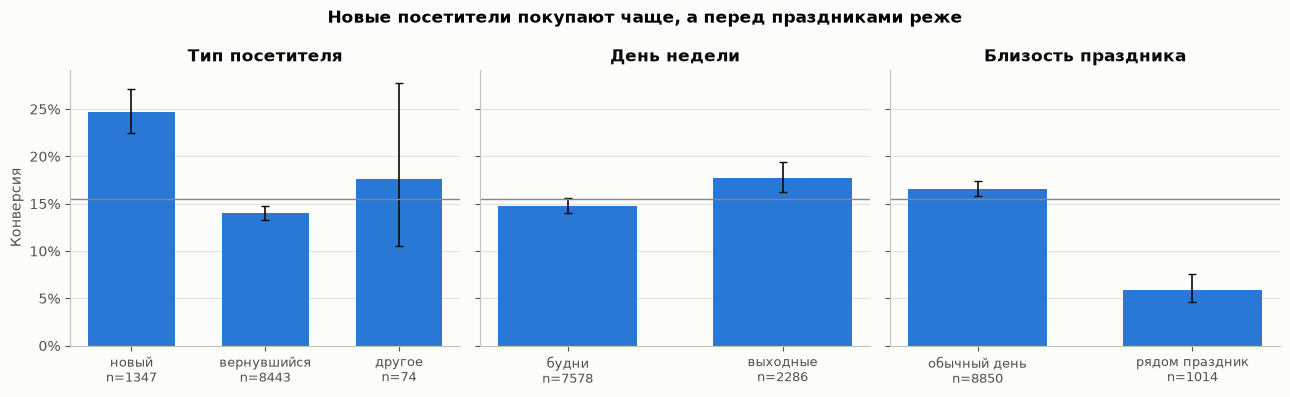

sessions  purchases  conversion  ci_low  \
тип посетителя New_Visitor            1347        333       0.247   0.225   
               Returning_Visitor      8443       1180       0.140   0.133   
               Other                    74         13       0.176   0.106   
выходные       0                      7578       1120       0.148   0.140   
               1                      2286        406       0.178   0.162   
праздник рядом 0                      8850       1466       0.166   0.158   
               1                      1014         60       0.059   0.046   

                                  ci_high  
тип посетителя New_Visitor          0.271  
               Returning_Visitor    0.147  
               Other                0.278  
выходные       0                    0.156  
               1                    0.194  
праздник рядом 0                    0.174  
               1                    0.075

In [6]:
by_visitor = conversion_table(train, "VisitorType").reindex(["New_Visitor", "Returning_Visitor", "Other"])
by_weekend = conversion_table(train, "Weekend")
train["special_day_flag"] = (train["SpecialDay"] > 0).astype(int)
by_special = conversion_table(train, "special_day_flag")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
plot_conversion_bars(axes[0], by_visitor, [VISITOR_RU[v] for v in by_visitor.index])
axes[0].set_title("Тип посетителя")
plot_conversion_bars(axes[1], by_weekend, ["будни", "выходные"])
axes[1].set_title("День недели")
plot_conversion_bars(axes[2], by_special, ["обычный день", "рядом праздник"])
axes[2].set_title("Близость праздника")
axes[0].set_ylabel("Конверсия")
fig.suptitle("Новые посетители покупают чаще, а перед праздниками реже", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_conversion_visitor_weekend_special")
plt.show()

pd.concat({"тип посетителя": by_visitor, "выходные": by_weekend, "праздник рядом": by_special})[
    ["sessions", "purchases", "conversion", "ci_low", "ci_high"]].round(3)

**Что увидел.**
- **Новые посетители** покупают чаще вернувшихся: 24.7% против 14.0%. Это противоположно моему ожиданию.
- **В выходные** конверсия немного выше: 17.8% против 14.8% в будни.
- **Рядом с праздником** (`SpecialDay > 0`) конверсия почти в 3 раза ниже: 5.9% против 16.6%. Тоже не то, что я ожидал.

**Что это значит.** Две из трёх догадок данные не поддерживают. Прежде чем верить таким выводам, нужно проверить, не объясняются ли они чем-то третьим. Например, праздники в данных могут приходиться на "плохие" месяцы, и тогда виноват месяц, а не праздник. Проверяю ниже.

### Праздник или месяц?

**Что хочу проверить.** В какие месяцы `SpecialDay > 0` и сохраняется ли эффект внутри одного месяца.

In [7]:
print("Сессий рядом с праздником по месяцам:")
print(pd.crosstab(train["Month"], train["special_day_flag"]).reindex(MONTH_ORDER)
      .rename(columns={0: "обычный день", 1: "рядом праздник"}))

for month in ["Feb", "May"]:
    t = conversion_table(train[train["Month"] == month], "special_day_flag")
    print(f"\n{MONTH_RU[month]}:")
    print(t[["sessions", "purchases", "conversion"]].rename(index={0: "обычный день", 1: "рядом праздник"}).round(3))

Сессий рядом с праздником по месяцам:
special_day_flag  обычный день  рядом праздник
Month                                         
Feb                         83              63
Mar                       1538               0
May                       1752             951
Jun                        228               0
Jul                        344               0
Aug                        342               0
Sep                        368               0
Oct                        444               0
Nov                       2360               0
Dec                       1391               0

фев:
                  sessions  purchases  conversion
special_day_flag                                 
обычный день            83          1       0.012
рядом праздник          63          1       0.016

май:
                  sessions  purchases  conversion
special_day_flag                                 
обычный день          1752        233       0.133
рядом праздник         951         5

**Что увидел.** `SpecialDay > 0` бывает только в феврале (14 февраля) и мае (День матери). В феврале покупок почти нет ни в какие дни (2 на 146 сессий). А вот **внутри мая** эффект сохраняется: рядом с праздником конверсия 6.2%, в остальные дни мая 13.3%.

**Что это значит.** Снижение конверсии рядом с праздником нельзя объяснить только месяцем. Возможное объяснение: перед праздником приходит много людей "посмотреть идеи подарков", которые покупают в другом месте или позже. Но это только догадка. Кроме того, праздников в данных по сути два, и для серьёзного вывода этого мало.

### Новые посетители: эффект месяца?

**Что хочу проверить.** Новых посетителей может быть больше в "хороших" месяцах (например, в ноябре). Тогда высокая конверсия новых объяснялась бы сезоном, а не типом посетителя. Сравниваю новых и вернувшихся внутри каждого месяца.

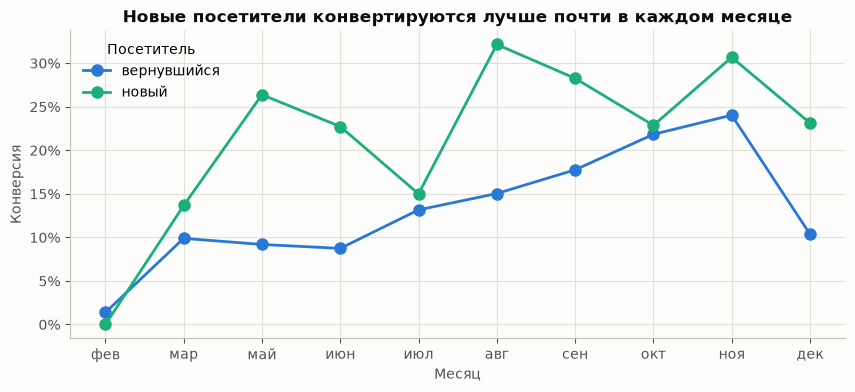

size                          mean                  
VisitorType New_Visitor Returning_Visitor New_Visitor Returning_Visitor
Month                                                                  
Feb                   1               145       0.000             0.014
Mar                 183              1355       0.137             0.099
May                 254              2449       0.264             0.092
Jun                  22               206       0.227             0.087
Jul                  40               304       0.150             0.132
Aug                  56               286       0.321             0.150
Sep                  92               276       0.283             0.178
Oct                 105               339       0.229             0.218
Nov                 326              2014       0.307             0.240
Dec                 268              1069       0.231             0.104

In [8]:
visitor_month = (train[train["VisitorType"] != "Other"]
                 .groupby(["Month", "VisitorType"])[TARGET].agg(["size", "mean"])
                 .unstack("VisitorType").reindex(MONTH_ORDER))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MONTH_ORDER))
for vt, color in [("Returning_Visitor", BLUE), ("New_Visitor", AQUA)]:
    ax.plot(x, visitor_month[("mean", vt)], marker="o", markersize=8, color=color,
            label=VISITOR_RU[vt])
ax.set_xticks(x)
ax.set_xticklabels([MONTH_RU[m] for m in MONTH_ORDER])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Новые посетители конвертируются лучше почти в каждом месяце")
ax.set_xlabel("Месяц")
ax.set_ylabel("Конверсия")
ax.legend(title="Посетитель")
save_fig(fig, "02_visitor_by_month")
plt.show()

visitor_month.round(3)

**Что увидел.** Новые посетители конвертируются лучше вернувшихся в 9 месяцах из 10. Исключение составляет февраль, где новых посетителей всего 1 человек. Например, в мае 26.4% у новых против 9.2% у вернувшихся, в ноябре 30.7% против 24.0%.

**Что это значит.** Это не эффект сезона. Возможные объяснения: "вернувшийся" посетитель часто заходит просто проверить статус заказа или ещё раз посмотреть товар, а новый приходит уже с намерением купить (например, по рекламе конкретного товара). Проверить это на этих данных нельзя. Для бизнес-симуляции это важно: если давать промокод всем новым посетителям, четверть из них купила бы и без него.

## 4. Источники трафика

**Что хочу проверить.** Отличается ли конверсия по источникам трафика (*источник трафика* показывает, откуда пришёл посетитель: поиск, реклама, рассылка и т.п.). Расшифровки кодов в данных нет, поэтому сравниваю только номера. Беру источники, у которых в train не меньше 100 сессий, остальные объединяю в "другие".

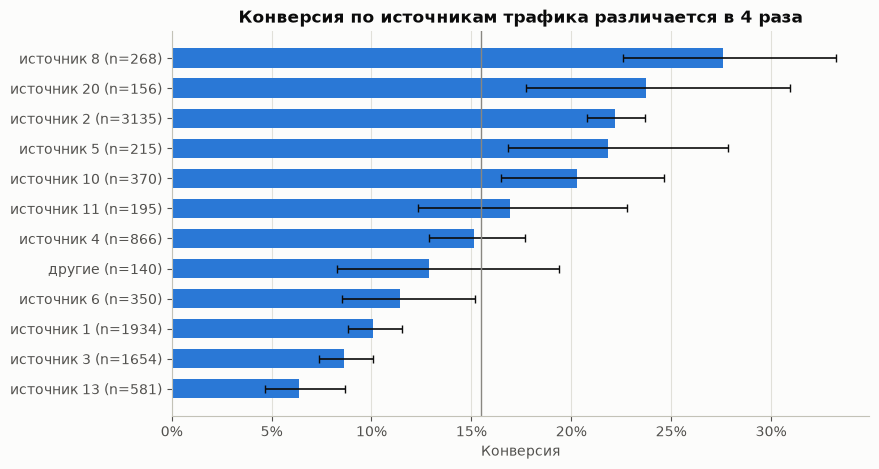

,sessions,purchases,conversion
traffic_group,,,
13,581,37,0.064
3,1654,143,0.086
1,1934,195,0.101
6,350,40,0.114
другие,140,18,0.129
4,866,131,0.151
11,195,33,0.169
10,370,75,0.203
5,215,47,0.219


In [9]:
min_sessions = 100
traffic_counts = train["TrafficType"].value_counts()
big_sources = traffic_counts[traffic_counts >= min_sessions].index
train["traffic_group"] = np.where(train["TrafficType"].isin(big_sources),
                                  train["TrafficType"].astype(str), "другие")
by_traffic = conversion_table(train, "traffic_group").sort_values("conversion")

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(by_traffic))
ax.barh(y_pos, by_traffic["conversion"], color=BLUE, height=0.65)
ax.errorbar(by_traffic["conversion"], y_pos,
            xerr=[by_traffic["conversion"] - by_traffic["ci_low"], by_traffic["ci_high"] - by_traffic["conversion"]],
            fmt="none", ecolor="#0b0b0b", elinewidth=1.2, capsize=3)
ax.axvline(base_conv, color=GRAY, linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels([f"источник {s} (n={n})" if s != "другие" else f"другие (n={n})"
                    for s, n in zip(by_traffic.index, by_traffic["sessions"])])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Конверсия по источникам трафика различается в 4 раза")
ax.set_xlabel("Конверсия")
ax.grid(axis="y", visible=False)
save_fig(fig, "02_conversion_by_traffic")
plt.show()
by_traffic[["sessions", "purchases", "conversion"]].round(3)

**Что увидел.** Лучшие крупные источники: 8 (27.6%), 20 (23.7%) и 2 (22.2%, самый массовый, 3135 сессий). Хуже всех 13 (6.4%), 3 (8.6%) и 1 (10.1%). Лучший крупный источник конвертирует примерно в 4 раза лучше худшего.

**Что это значит.** Источник трафика оказался сильным признаком. Бизнес-вывод сделать трудно, потому что неизвестно, что стоит за номерами. Если бы знать, что "13" означает, например, дешёвую баннерную рекламу, можно было бы пересмотреть бюджет.

## 5. Время на товарных страницах и покупка

**Что хочу проверить.** Главный вопрос проекта: растёт ли вероятность покупки с ростом времени на товарных страницах, и если да, то равномерно ли. Делю сессии на 10 равных по численности групп (*децилей*) по времени на товарных страницах и считаю конверсию в каждой.

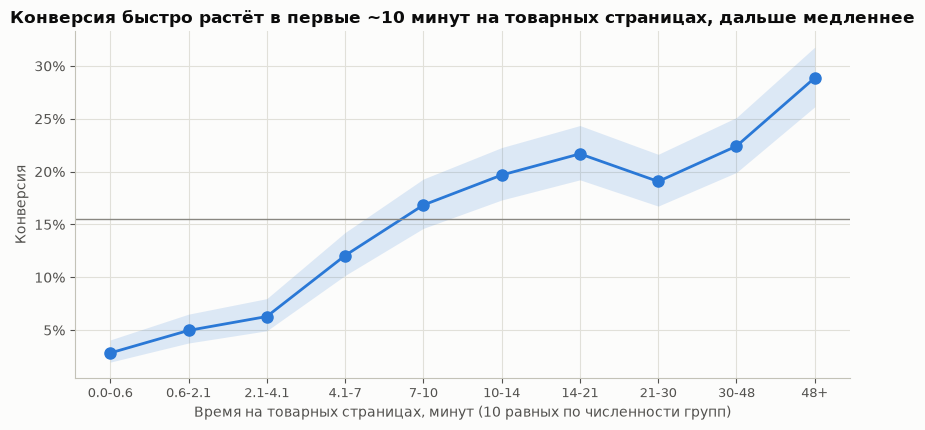

,"от, мин","до, мин",sessions,conversion
duration_decile,,,,
0,0.0,0.6,987,0.028
1,0.6,2.1,986,0.050
2,2.1,4.1,986,0.063
3,4.1,6.7,987,0.121
4,6.7,10.0,986,0.168
5,10.0,14.2,986,0.197
6,14.2,20.5,987,0.217
7,20.5,29.7,986,0.191
8,29.7,47.6,986,0.224


In [10]:
train["duration_decile"] = pd.qcut(train["ProductRelated_Duration"].rank(method="first"), 10, labels=False)
by_decile = conversion_table(train, "duration_decile")
decile_ranges = train.groupby("duration_decile")["ProductRelated_Duration"].agg(["min", "max"])
by_decile = by_decile.join(decile_ranges)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(10)
ax.fill_between(x, by_decile["ci_low"], by_decile["ci_high"], color=BLUE, alpha=0.15, linewidth=0)
ax.plot(x, by_decile["conversion"], marker="o", markersize=8, color=BLUE)
ax.axhline(base_conv, color=GRAY, linewidth=1)
ax.set_xticks(x)
def fmt_min(sec):
    return f"{sec / 60:.1f}" if sec < 300 else f"{sec / 60:.0f}"
ax.set_xticklabels([f"{fmt_min(lo)}-{fmt_min(hi)}" if i < 9 else f"{fmt_min(lo)}+"
                    for i, (lo, hi) in enumerate(zip(by_decile["min"], by_decile["max"]))], fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Конверсия быстро растёт в первые ~10 минут на товарных страницах, дальше медленнее")
ax.set_xlabel("Время на товарных страницах, минут (10 равных по численности групп)")
ax.set_ylabel("Конверсия")
save_fig(fig, "02_conversion_vs_product_time")
plt.show()

out = by_decile[["min", "max", "sessions", "conversion"]].copy()
out[["min", "max"]] = (out[["min", "max"]] / 60).round(1)
out.rename(columns={"min": "от, мин", "max": "до, мин"}).round(3)

**Что увидел.** В первой группе (до 0.6 минуты на товарных страницах) покупают 2.8% сессий. Дальше конверсия быстро растёт: 12.1% в группе 4-7 минут, 19.7% в группе 10-14 минут. Потом почти выходит на плато: от 10 до 48 минут она держится в районе 19-22%. И только в последней группе (больше 48 минут) она поднимается до 28.9%.

**Что это значит.** Связь есть, но она *нелинейная*: первые минуты на товарных страницах сильно отличают "зашёл и ушёл" от "выбирает", а дальше каждая следующая минута добавляет мало. Для модели это подсказка: логарифм времени или деревья решений должны описать такую форму лучше, чем "сырое" время в линейной модели.

Важная оговорка: это связь, а не причина. Тот, кто уже решил купить, проводит на сайте больше времени, потому что выбирает размер, читает характеристики и оформляет заказ. Если заставить человека сидеть на странице дольше, он не станет от этого покупать чаще.

## 6. PageValues

**Что хочу проверить.** Как ведёт себя признак "ценность страниц", о котором я в 01 записал подозрение на утечку.

In [11]:
train["pv_positive"] = (train["PageValues"] > 0).astype(int)
by_pv = conversion_table(train, "pv_positive")
print(by_pv[["sessions", "purchases", "conversion"]].rename(index={0: "PageValues = 0", 1: "PageValues > 0"}).round(3))

share_buyers_pv = train.loc[train[TARGET] == 1, "pv_positive"].mean()
share_nonbuyers_pv = train.loc[train[TARGET] == 0, "pv_positive"].mean()
print(f"\nДоля сессий с PageValues > 0 среди купивших: {share_buyers_pv:.1%}")
print(f"Доля сессий с PageValues > 0 среди не купивших: {share_nonbuyers_pv:.1%}")

                sessions  purchases  conversion
pv_positive                                    
PageValues = 0      7671        286       0.037
PageValues > 0      2193       1240       0.565

Доля сессий с PageValues > 0 среди купивших: 81.3%
Доля сессий с PageValues > 0 среди не купивших: 11.4%


**Что увидел.** Если `PageValues = 0`, покупают 3.7% сессий. Если больше нуля, покупают 56.5%, то есть в 15 раз чаще. У 81.3% купивших `PageValues > 0`, а у не купивших только у 11.4%.

**Что это значит.** Это самый сильный признак из всех. Слишком сильный, и это подозрительно. По определению Google Analytics, ценность страницы считается из выручки покупок, перед которыми эту страницу смотрели. Если в расчёт попала выручка этой же сессии, признак частично "знает ответ". Подробно разберу в 04 и проверю модели с ним и без него.

## 7. Показатели отказов и выхода

**Что хочу проверить.** Отличаются ли средние показатели отказов и выхода страниц, которые посмотрели купившие и ушедшие.

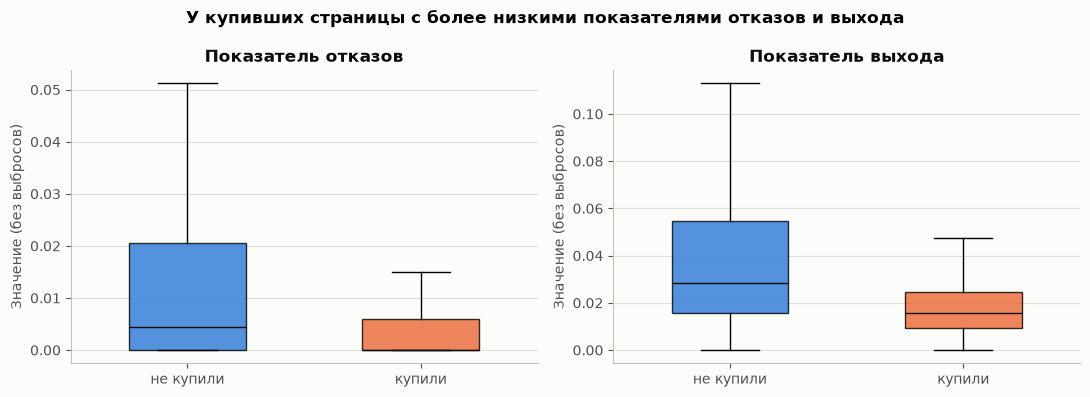

,BounceRates,ExitRates
Revenue,,
не купили,0.0043,0.0286
купили,0.0000,0.0157


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["BounceRates", "ExitRates"]):
    data = [train.loc[train[TARGET] == cls, col] for cls in [0, 1]]
    bp = ax.boxplot(data, tick_labels=[CLASS_LABELS[0], CLASS_LABELS[1]], widths=0.5,
                    patch_artist=True, showfliers=False, medianprops={"color": "#0b0b0b"})
    for patch, cls in zip(bp["boxes"], [0, 1]):
        patch.set_facecolor(CLASS_COLORS[cls])
        patch.set_alpha(0.8)
    ax.set_title(FEATURE_RU[col])
    ax.set_ylabel("Значение (без выбросов)")
    ax.grid(axis="x", visible=False)
fig.suptitle("У купивших страницы с более низкими показателями отказов и выхода", fontweight="bold")
fig.tight_layout()
plt.show()
train.groupby(TARGET)[["BounceRates", "ExitRates"]].median().rename(index=CLASS_LABELS).round(4)

**Что увидел.** Медиана показателя выхода у купивших 0.016, у ушедших 0.029. Медиана показателя отказов у купивших ноль, у ушедших 0.004.

**Что это значит.** Купившие ходят по страницам, с которых обычно не уходят (например, корзина или оформление заказа ведут дальше). Тут тоже есть опасность "обратной причинности": страницы оформления заказа имеют низкий показатель выхода именно потому, что их смотрят те, кто покупает.

*Обратная причинность* бывает, когда кажется, что A вызывает B, а на деле B вызывает A.

## 8. Как признаки связаны между собой

**Что хочу проверить.** Есть ли сильно связанные между собой признаки. Они дублируют друг друга, и это мешает интерпретировать коэффициенты линейной модели. Использую корреляцию Спирмена: она показывает, насколько согласованно растут два признака, и не боится выбросов, потому что работает с рангами (местами в упорядоченном списке), а не с самими значениями. Значения от -1 до 1, 0 означает, что связи нет.

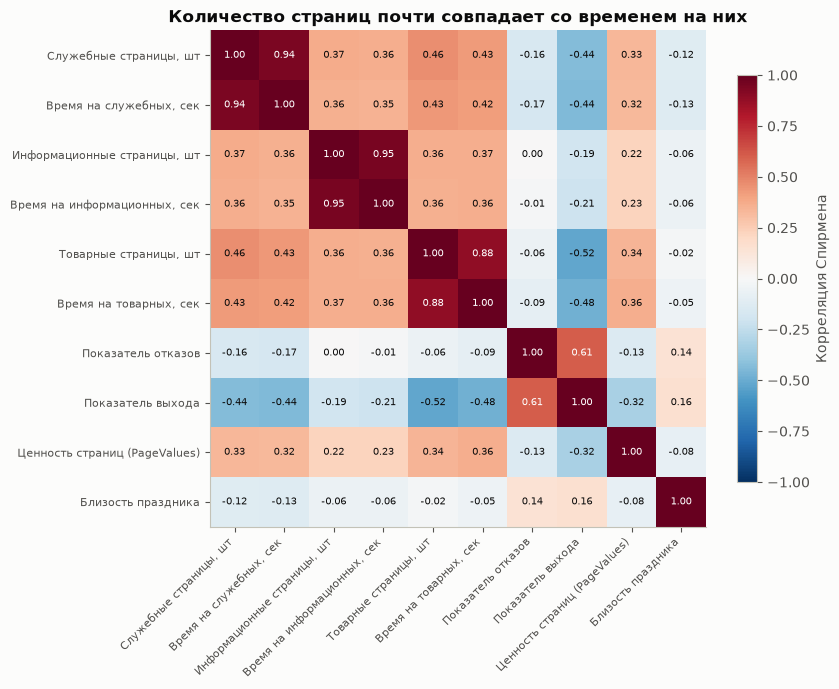

,,Спирмен
Informational,Informational_Duration,0.95
Administrative,Administrative_Duration,0.94
ProductRelated,ProductRelated_Duration,0.88
BounceRates,ExitRates,0.61
ProductRelated,ExitRates,-0.52
ProductRelated_Duration,ExitRates,-0.48


In [13]:
corr = train[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
labels = [FEATURE_RU[c] for c in num_cols]
ax.set_xticks(range(len(num_cols)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(num_cols)))
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Корреляция Спирмена")
ax.set_title("Количество страниц почти совпадает со временем на них")
fig.tight_layout()
save_fig(fig, "02_spearman_corr")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .sort_values(key=abs, ascending=False).head(6))
pairs.round(2).to_frame("Спирмен")

**Что увидел.** Самые сильные связи: число служебных страниц и время на них (0.94), то же для информационных (0.95) и товарных (0.88). Показатели отказов и выхода связаны на 0.61. С остальными признаками связи умеренные или слабые.

**Что это значит.** "Сколько страниц" и "сколько времени" почти дублируют друг друга. Отсюда идея для признаков: вместо двух почти одинаковых чисел использовать "среднее время на одну страницу". Оно несёт другую информацию (вдумчиво читает или быстро листает).

## Гипотезы, появившиеся по ходу

1. **Гипотеза:** купившие проводят на товарных страницах больше времени, чем не купившие.
   **Почему я так думаю:** медиана 1121 сек против 511 сек, конверсия растёт с временем от 2.8% до 28.9%.
   **Как проверить:** U-критерий Манна-Уитни (распределения сильно скошены, поэтому проверку на нормальность ожидаю провалить; проверю в 03). Размер эффекта: вероятность превосходства и разница медиан с бутстрэп-интервалом.

2. **Гипотеза:** новые посетители покупают чаще вернувшихся.
   **Почему я так думаю:** 24.7% против 14.0%, и это держится почти в каждом месяце.
   **Как проверить:** хи-квадрат на таблице 2×2 "тип посетителя × покупка". Размер эффекта: разница конверсий и V Крамера.

3. **Гипотеза:** в выходные конверсия выше, чем в будни.
   **Почему я так думаю:** 17.8% против 14.8%, но разница небольшая и может оказаться шумом.
   **Как проверить:** хи-квадрат 2×2, размер эффекта.

4. **Гипотеза:** рядом с праздником конверсия ниже, и дело не только в месяце.
   **Почему я так думаю:** в мае 6.2% рядом с праздником против 13.3% в остальные дни.
   **Как проверить:** хи-квадрат 2×2 только внутри мая (чтобы убрать влияние месяца).

5. **Гипотеза:** конверсия зависит от источника трафика.
   **Почему я так думаю:** разброс от 6.4% до 27.6% среди крупных источников.
   **Как проверить:** хи-квадрат на таблице "источник × покупка" (редкие источники объединены), V Крамера.

6. **Гипотеза:** `PageValues` содержит информацию о самой покупке (утечка).
   **Почему я так думаю:** конверсия 56.5% при `PageValues > 0` против 3.7% при нуле, а по определению признак считается из выручки.
   **Как проверить:** разобрать определение и сравнить модели с признаком и без него (ноутбук 04).

7. **Гипотеза:** после примерно 10 минут на товарных страницах время почти не добавляет информации о покупке.
   **Почему я так думаю:** плато на графике по децилям.
   **Как проверить:** в 04 сравнить логистическую регрессию на сыром и логарифмированном времени.

## Итоги

- **Сезонность сильная:** конверсия от 1.4% в феврале до 24.8% в ноябре.
- **Новые посетители покупают чаще вернувшихся** (24.7% против 14.0%) почти в каждом месяце, вопреки моему ожиданию.
- **Время на товарных страницах связано с покупкой нелинейно:** от 2.8% в нижней группе до примерно 20% у сессий длиннее ~10 минут, дальше почти плато.
- **Рядом с праздниками конверсия ниже** (5.9% против 16.6%), и в мае это видно и внутри месяца.
- **`PageValues` подозрительно сильный признак:** 56.5% конверсии при значении больше нуля против 3.7% при нуле.

## Что не получилось или удивило

- Две мои "очевидные" догадки (вернувшиеся покупают чаще, перед праздниками покупают чаще) данные не подтвердили, даже наоборот.
- Декабрь оказался заметно хуже ноября (13.2% против 24.8%).
- Расшифровки источников трафика нет, поэтому сильный признак почти не даёт бизнес-выводов.

## Новые идеи

- Признак "среднее время на одну товарную страницу" (отличает вдумчивое чтение от пролистывания).
- Учесть, что купившие могут "накручивать" страницы и время самим оформлением заказа. Это ограничение для интерпретации, а не только для модели.

## Следующие шаги

- **В ноутбуке 03** проверю гипотезы 1-5 статистически с поправкой на множественные сравнения.
- **При большем времени:** найти данные с расшифровкой источников трафика и точными датами, чтобы проверить сезонность и праздники на нескольких годах.